# K-Means con Restricciones de Tamaño: el Método del Lagrangiano

**Duración estimada:** 60 min · **Nivel:** primera vez con optimización con restricciones

## Objetivos
Al terminar este notebook podrás:
1. Explicar por qué K-Means estándar puede producir soluciones **no factibles**.
2. Formular una restricción de capacidad como parte de un **Lagrangiano**.
3. Interpretar el multiplicador $\lambda$ como un **precio sombra**.
4. Implementar un algoritmo **primal-dual** que obtiene clusters factibles.

## Escenario práctico
Tienes **6 servidores** y debes repartirlos en **2 clusters** (por ejemplo, 2 salas de
datos) según su similitud (carga de CPU y memoria). Pero cada sala tiene capacidad
física limitada: **ningún cluster puede tener más de 3 servidores**.

## ¿Por qué falla el K-Means estándar?
K-Means solo minimiza la distancia a los centroides. **No sabe** que existe un límite
de capacidad (físico, regulatorio, de licencias, de refrigeración...). Si cuatro
servidores son parecidos entre sí, K-Means los pondrá juntos y **violará** la restricción.

> **Idea clave:** en lugar de prohibir la violación con una regla rígida, la
> *convertiremos en un costo* que el algoritmo aprende a pagar o evitar.

## Fundamento Matemático

### 1. Función de costo estándar (SSE)
Con $N$ puntos $x_i \in \mathbb{R}^d$, $K$ clusters, centroides $\mu_j$ y asignaciones
binarias $z_{ij}\in\{0,1\}$ (con $\sum_j z_{ij}=1$):

$$
\text{SSE}(z,\mu)=\sum_{i=1}^{N}\sum_{j=1}^{K} z_{ij}\,\lVert x_i-\mu_j\rVert^2
$$

### 2. Restricción de desigualdad (capacidad máxima)
El tamaño del cluster $j$ es $n_j=\sum_{i} z_{ij}$. Exigimos

$$
g_j(z) = n_j - C_{\max} \le 0 \qquad \forall j=1,\dots,K
$$

Aquí $g_j>0$ significa **violación** (el cluster excede su capacidad).

### 3. El Lagrangiano
Asociamos un multiplicador $\lambda_j \ge 0$ a cada restricción:

$$
\mathcal{L}(z,\mu,\lambda)=\underbrace{\sum_{i,j} z_{ij}\lVert x_i-\mu_j\rVert^2}_{\text{SSE}}
+\sum_{j=1}^{K}\lambda_j\underbrace{\big(n_j-C_{\max}\big)}_{\text{Violación}}
$$

### 4. El rol de $\lambda_j$: penalización y precio sombra
- Si $n_j>C_{\max}$, el término $\lambda_j(n_j - C_{\max})$ **suma costo** → el algoritmo prefiere sacar puntos del cluster $j$.
- $\lambda_j$ es el **"precio" por punto** de pertenecer al cluster $j$: cada punto asignado
  a $j$ paga $\lambda_j$ extra. Por eso la asignación óptima de cada punto pasa a ser:

$$
z_i=\arg\min_{j}\ \Big(\lVert x_i-\mu_j\rVert^2+\lambda_j\Big)
$$

- **Precio sombra:** en el óptimo, $\lambda_j^\star$ mide cuánto *mejoraría* el SSE si
  relajáramos la capacidad $C_{\max}$ en una unidad (cuánto "cuesta" la restricción).
- **Holgura complementaria (KKT):** $\lambda_j\,(n_j-C_{\max})=0$. O la restricción está
  activa ($n_j=C_{\max}$) y $\lambda_j\ge0$ puede ser positivo, o hay holgura y $\lambda_j=0$.


Tamaños de cluster (K-Means estándar): [4 2]


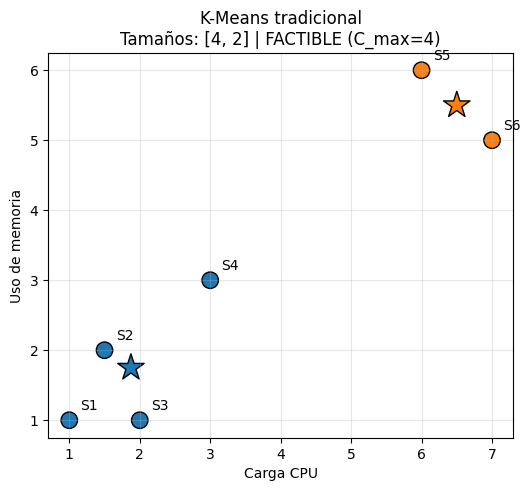

In [8]:
# ============================================================
# Celda 1: Toy dataset + K-Means tradicional (ignora la restricción)
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 6 servidores descritos por (carga CPU, uso de memoria)
X = np.array([[1.0, 1.0],   # S1
              [1.5, 2.0],   # S2
              [2.0, 1.0],   # S3
              [3.0, 3.0],   # S4  <- punto "frontera"
              [6.0, 6.0],   # S5
              [7.0, 5.0]])  # S6

K, C_MAX = 2, 4   # 2 clusters, capacidad máxima de 3 servidores por cluster

def plot_clusters(ax, X, labels, mu, title, C=C_MAX):
    """Dibuja puntos, centroides y el tamaño de cada cluster."""
    colors = np.array(["tab:blue", "tab:orange"])
    counts = np.bincount(labels, minlength=len(mu))
    ax.scatter(X[:, 0], X[:, 1], c=colors[labels], s=140, edgecolor="k")
    for i, (x, y) in enumerate(X):
        ax.annotate(f"S{i+1}", (x, y), textcoords="offset points", xytext=(8, 8))
    ax.scatter(mu[:, 0], mu[:, 1], c=colors[:len(mu)], marker="*", s=400, edgecolor="k")
    estado = "VIOLA" if np.any(counts > C) else "FACTIBLE"
    ax.set_title(f"{title}\nTamaños: {counts.tolist()} | {estado} (C_max={C})")
    ax.set_xlabel("Carga CPU"); ax.set_ylabel("Uso de memoria"); ax.grid(alpha=0.3)

# K-Means estándar
km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(X)
labels_km, mu_km = km.labels_, km.cluster_centers_
print("Tamaños de cluster (K-Means estándar):", np.bincount(labels_km))

fig, ax = plt.subplots(figsize=(6, 5))
plot_clusters(ax, X, labels_km, mu_km, "K-Means tradicional")
plt.show()

# Pregunta rápida: ¿qué cluster excede C_MAX y por cuántos puntos?

## Guía del Algoritmo Primal-Dual

Alternamos entre minimizar sobre las variables **primales** ($z,\mu$) y hacer
*ascenso* sobre las variables **duales** ($\lambda$). En cada iteración $t$:

**Paso 1 — Asignación penalizada (primal).**
Cada punto elige el cluster con menor *distancia + precio*:
$$z_i=\arg\min_j\ \lVert x_i-\mu_j\rVert^2+\lambda_j$$
→ Si $\lambda_j$ es grande, el cluster $j$ se vuelve "caro" y los puntos más
  marginales migran a otro cluster.

**Paso 2 — Actualización de centroides (primal).**
$$\mu_j=\frac{1}{n_j}\sum_{i:\,z_i=j}x_i$$

**Paso 3 — Ascenso dual (ajuste del precio).**
$$\lambda_j \leftarrow \max\big(0,\ \lambda_j+\eta\,(n_j-C_{\max})\big)$$
- Si $n_j>C_{\max}$ (violación) → **$\lambda_j$ sube**: el cluster se encarece.
- Si $n_j<C_{\max}$ (holgura) → **$\lambda_j$ baja** (nunca por debajo de 0).
- Si $n_j=C_{\max}$ → **$\lambda_j$ se queda igual**: precio de equilibrio.

**Parada:** cuando las asignaciones no cambian **y** todos los $n_j\le C_{\max}$.

> $\eta>0$ es el *tamaño de paso* dual: pequeño = estable pero lento; grande = rápido
> pero puede oscilar. Aquí usaremos $\eta=2$.

### Plan sugerido de 30 min
| Tiempo | Actividad |
|---|---|
| 0–5 min | Celdas de Markdown 1 y 2 (escenario y teoría) |
| 5–10 min | Celda de código 1 (K-Means tradicional) |
| 10–15 min | Esta guía del algoritmo |
| 15–20 min | Celda de código 2 (implementación y experimentos con $\eta$, $C_{\max}$) |
| 50–60 min | Autoevaluación |

Iteraciones: 2 | λ final = [0. 0.]
Tamaños: [4 2] | SSE estándar = 5.94 -> SSE con restricción = 5.94


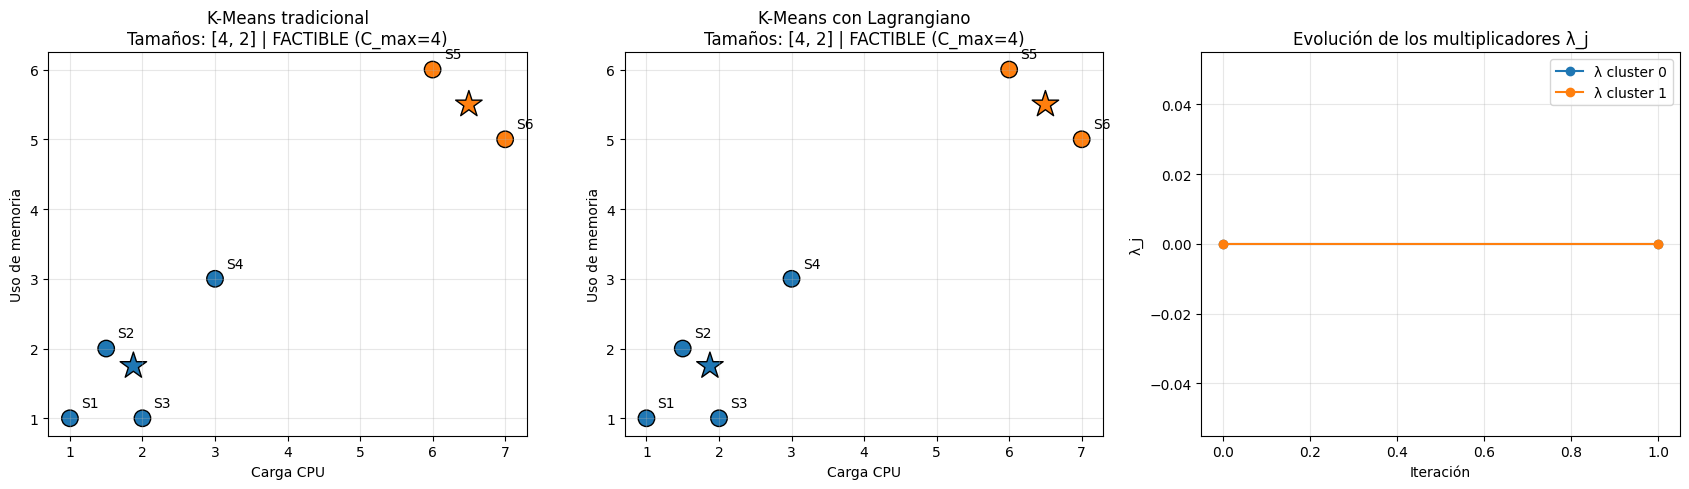

In [9]:
# ============================================================
# Celda 2: Constrained K-Means con Lagrangiano (primal-dual)
# ============================================================
def constrained_kmeans(X, mu0, C, eta=2.0, max_iter=200):
    K = len(mu0)
    mu, lam, prev = mu0.copy(), np.zeros(K), None   # λ_j = 0 al inicio
    hist_lam = []
    for t in range(max_iter):
        # --- Paso 1 (primal): asignación con costo = distancia² + λ_j
        D = ((X[:, None, :] - mu[None, :, :]) ** 2).sum(axis=2)   # (N, K)
        labels = np.argmin(D + lam[None, :], axis=1)
        # --- Paso 2 (primal): actualizar centroides
        for j in range(K):
            if np.any(labels == j):
                mu[j] = X[labels == j].mean(axis=0)
        # --- Paso 3 (dual): ascenso de λ proyectado a λ >= 0
        counts = np.bincount(labels, minlength=K)
        lam = np.maximum(0.0, lam + eta * (counts - C))
        hist_lam.append(lam.copy())
        # --- Criterio de parada: asignaciones estables y solución factible
        if prev is not None and np.array_equal(labels, prev) and np.all(counts <= C):
            break
        prev = labels.copy()
    return labels, mu, lam, np.array(hist_lam)

# Inicializamos con los centroides del K-Means estándar
labels_c, mu_c, lam_final, hist_lam = constrained_kmeans(X, mu_km, C_MAX, eta=2.0)

sse = lambda lab, mu: sum(((X[lab == j] - mu[j]) ** 2).sum() for j in range(K))
print(f"Iteraciones: {len(hist_lam)} | λ final = {np.round(lam_final, 2)}")
print(f"Tamaños: {np.bincount(labels_c)} | SSE estándar = {sse(labels_km, mu_km):.2f}"
      f" -> SSE con restricción = {sse(labels_c, mu_c):.2f}")

# --- Visualización comparativa + evolución de λ
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
plot_clusters(axes[0], X, labels_km, mu_km, "K-Means tradicional")
plot_clusters(axes[1], X, labels_c, mu_c, "K-Means con Lagrangiano")
axes[2].plot(hist_lam, marker="o")
axes[2].set_title("Evolución de los multiplicadores λ_j")
axes[2].set_xlabel("Iteración"); axes[2].set_ylabel("λ_j")
axes[2].legend([f"λ cluster {j}" for j in range(K)]); axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

# 🧪 Experimenta: cambia eta (0.5, 5, 20), C_MAX = 4 o K = 3 y observa qué pasa con λ.

## 🧠 Autoevaluación y Preguntas de Reflexión

**1. Papel de $\lambda$.**
En la gráfica de evolución de $\lambda$, ¿por qué el multiplicador del cluster
sobrecargado sube durante varias iteraciones y luego **deja de cambiar**? ¿Qué relación
tiene esto con la condición de holgura complementaria $\lambda_j(n_j-C_{\max})=0$?
¿Qué le pasa a $\lambda$ del otro cluster y por qué?

**2. Convergencia.**
Prueba $\eta=0.5$ y $\eta=20$. ¿Cómo cambia el número de iteraciones? ¿Qué riesgo
aparece con un paso demasiado grande? ¿Y con uno demasiado pequeño?

**3. Factibilidad y precio sombra.**
Si subes $C_{\max}$ de 3 a 4, ¿qué esperas que ocurra con $\lambda$ y con el SSE?
Interpreta el valor final de $\lambda$ como el "precio" de la restricción de capacidad.
¿Sería posible que el problema fuera infactible? (Pista: ¿qué relación debe cumplirse
entre $N$, $K$ y $C_{\max}$?)